# Plate Detector Training — Paper Setup

Reproduces the YOLOv8m licence plate localization experiments of Hasin et al. (2026) on the Hossain localization dataset with its original splits (5,687 / 277 / 553).

| Experiment | Description |
|---|---|
| `yolov8m-paper` | YOLOv8m, single stage |
| `yolov8m-paper-2stage` | YOLOv8m with the paper's two-stage adaptive training |

**Two-stage training**
- Batch size 10.
- **Stage 1**, 35 epochs: high learning rate; 12 frozen layers, then 8, then 4; spatial augmentation (±8° rotation, 15% translation, 0.7 scale, ±3° shear, 100% mosaic, 15% mix-up, 40% copy-paste, 50% horizontal flip) with moderate colour changes (hue 1%, saturation 80%, brightness 50%); early-stopping patience 15.
- **Stage 2**: if stage 1 reaches mAP > 0.7, 45 epochs fully unfrozen with a conservative learning rate; otherwise 55 epochs with light freezing and a moderate learning rate. Reduced spatial augmentation (±3°, 8%, 0.4, ±1°, 70% mosaic, 8% mix-up, 20% copy-paste, 30% flip), stronger colour changes (hue 2%, saturation 90%, brightness 70%), and cosine-annealed learning rate.

**Not stated in the paper, chosen here:** image size 640; SGD; stage 1 learning rate 0.01, momentum 0.95, weight decay 0.001; stage 2 learning rate 0.001 (0.005 on the fallback path), momentum 0.9, weight decay 0.0005; frozen-layer changes at epochs 12 and 24 of stage 1; "light freezing" as 4 layers. The single-stage baseline is not described in the paper and uses Ultralytics defaults for 80 epochs.

**Setup (Kaggle notebook)**
1. Add `bangla-licence-plates` as an input.
2. Accelerator: **GPU**.

In [1]:
%pip install -q ultralytics==8.4.46

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 39.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## Configuration

In [3]:
EXPERIMENT = "yolov8m-paper-2stage"   # or "yolov8m-paper"

MODEL = "yolov8m.pt"
BATCH = 10
IMGSZ = 640
SEED = 0
BASELINE_EPOCHS = 80

## Setup

In [4]:
import json
import shutil
import xml.etree.ElementTree as ET
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from ultralytics import YOLO

WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")
RUNS = WORK / "runs"
DEVICE = 0 if torch.cuda.is_available() else "cpu"


def find_input(name: str) -> Path:
    return next(p for p in INPUT.rglob(name) if p.is_dir())


print(f"Experiment: {EXPERIMENT}\nDevice: {DEVICE}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Experiment: yolov8m-paper-2stage
Device: 0


## Prepare data

The Hossain localization set is converted to YOLO format with its original splits.

In [5]:
def build_paper_dataset(target: Path) -> Path:
    source = find_input("bangla-licence-plates") / "bd-lpr" / "License Plate Localization"
    for src_split, split in {"train": "train", "validation": "val", "test": "test"}.items():
        (target / "images" / split).mkdir(parents=True, exist_ok=True)
        (target / "labels" / split).mkdir(parents=True, exist_ok=True)
        for image in (source / src_split).glob("*.jpg"):
            root = ET.parse(image.with_suffix(".xml")).getroot()
            width, height = Image.open(image).size
            lines = []
            for obj in root.iter("object"):
                b = obj.find("bndbox")
                x1, y1, x2, y2 = (float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
                x1, x2, y1, y2 = max(0, x1), min(width, x2), max(0, y1), min(height, y2)
                if x2 > x1 and y2 > y1:
                    lines.append(f"0 {(x1 + x2) / 2 / width:.6f} {(y1 + y2) / 2 / height:.6f} "
                                 f"{(x2 - x1) / width:.6f} {(y2 - y1) / height:.6f}")
            shutil.copy2(image, target / "images" / split / f"bd-lpr__{image.name}")
            (target / "labels" / split / f"bd-lpr__{image.stem}.txt").write_text("\n".join(lines))
    (target / "data.yaml").write_text(
        "train: images/train\nval: images/val\ntest: images/test\nnames:\n  0: license_plate\n")
    return target


DATA = WORK / "plate-detection-paper"
if not DATA.exists():
    build_paper_dataset(DATA)

DATA_YAML = DATA / "data.yaml"
for split in ("train", "val", "test"):
    print(f"{split:5} {len(list((DATA / 'images' / split).iterdir())):6d} images")

train   5687 images
val      277 images
test     553 images


## Train

In [6]:
COMMON = dict(data=str(DATA_YAML), imgsz=IMGSZ, batch=BATCH, device=DEVICE, seed=SEED,
              project=str(RUNS), exist_ok=True)

STAGE_1 = dict(epochs=35, patience=15, freeze=12,
               optimizer="SGD", lr0=0.01, momentum=0.95, weight_decay=0.001,
               degrees=8, translate=0.15, scale=0.7, shear=3, perspective=0.0, flipud=0.0, fliplr=0.5,
               mosaic=1.0, mixup=0.15, copy_paste=0.4, hsv_h=0.01, hsv_s=0.8, hsv_v=0.5)
STAGE_2 = dict(optimizer="SGD", momentum=0.9, weight_decay=0.0005, cos_lr=True, warmup_epochs=0,
               degrees=3, translate=0.08, scale=0.4, shear=1, perspective=0.0, flipud=0.0, fliplr=0.3,
               mosaic=0.7, mixup=0.08, copy_paste=0.2, hsv_h=0.02, hsv_s=0.9, hsv_v=0.7)
UNFREEZE_AT = {12: 8, 24: 4}   # stage 1 epoch (0-based) -> number of layers that stay frozen


def progressive_unfreeze(trainer):
    frozen = UNFREEZE_AT.get(trainer.epoch)
    if frozen is None:
        return
    for name, param in trainer.model.named_parameters():
        parts = name.split(".")
        if parts[0] == "model" and parts[1].isdigit() and frozen <= int(parts[1]) < 12:
            param.requires_grad = True
    print(f"Epoch {trainer.epoch + 1}: {frozen} layers frozen")


if EXPERIMENT == "yolov8m-paper-2stage":
    stage1 = YOLO(MODEL)
    stage1.add_callback("on_train_epoch_start", progressive_unfreeze)
    stage1.train(**COMMON, **STAGE_1, name=f"{EXPERIMENT}-stage1")
    STAGE1_RUN = RUNS / f"{EXPERIMENT}-stage1"

    stage1_map = pd.read_csv(STAGE1_RUN / "results.csv").rename(columns=str.strip)["metrics/mAP50(B)"].max()
    converged = stage1_map > 0.7
    print(f"Stage 1 best mAP@0.5: {stage1_map:.4f} -> {'converged' if converged else 'not converged'}")

    stage2 = dict(epochs=45, freeze=None, lr0=0.001) if converged else dict(epochs=55, freeze=4, lr0=0.005)
    YOLO(STAGE1_RUN / "weights" / "best.pt").train(**COMMON, **STAGE_2, **stage2, patience=0,
                                                   name=f"{EXPERIMENT}-stage2")
    RUN = RUNS / f"{EXPERIMENT}-stage2"
    STAGE_RUNS = [STAGE1_RUN, RUN]
else:
    YOLO(MODEL).train(**COMMON, epochs=BASELINE_EPOCHS, patience=0, name=EXPERIMENT)
    RUN = RUNS / EXPERIMENT
    STAGE_RUNS = [RUN]

print("Final weights:", RUN / "weights" / "best.pt")

New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.46 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=10, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.4, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/plate-detection-paper/data.yaml, degrees=8, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=35, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=12, half=False, hsv_h=0.01, hsv_s=0.8, hsv_v=0.5, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolov8m.pt, momentum=0.95, mosaic=1.0, multi_scale=0

## Training curves

Epochs: 79  best epoch 42: mAP@0.5 0.9903  mAP@0.5:0.95 0.7763


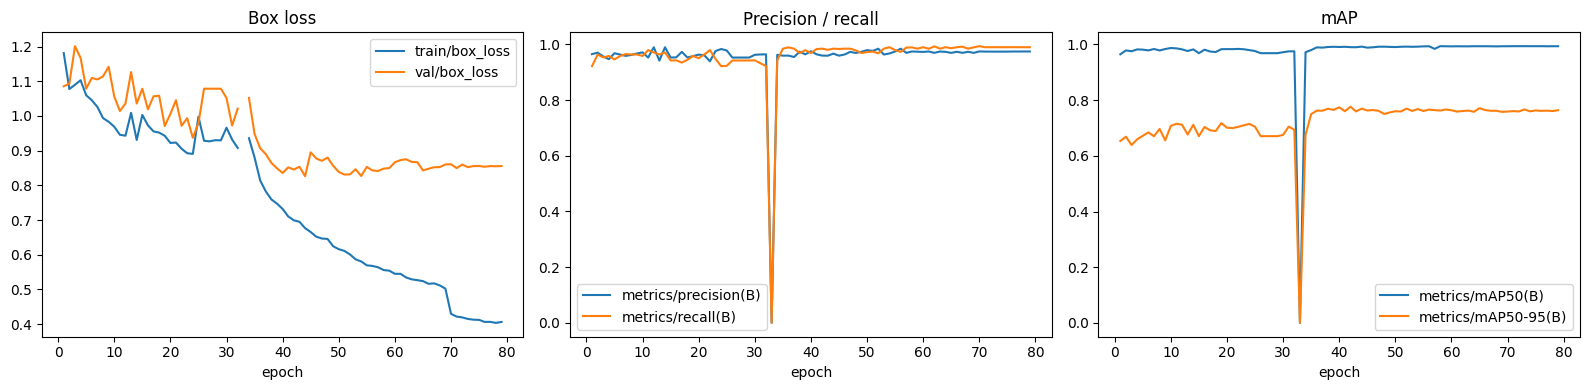

In [7]:
import matplotlib.pyplot as plt

df = pd.concat([pd.read_csv(r / "results.csv") for r in STAGE_RUNS], ignore_index=True)
df.columns = df.columns.str.strip()
df["epoch"] = range(1, len(df) + 1)
best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
print(f"Epochs: {len(df)}  best epoch {int(best['epoch'])}: "
      f"mAP@0.5 {best['metrics/mAP50(B)']:.4f}  mAP@0.5:0.95 {best['metrics/mAP50-95(B)']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for keys, ax, title in [
    (("train/box_loss", "val/box_loss"), axes[0], "Box loss"),
    (("metrics/precision(B)", "metrics/recall(B)"), axes[1], "Precision / recall"),
    (("metrics/mAP50(B)", "metrics/mAP50-95(B)"), axes[2], "mAP"),
]:
    for key in keys:
        ax.plot(df["epoch"], df[key], label=key)
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

In [8]:
import shutil

shutil.make_archive(
    "/kaggle/working/runs",
    "zip",
    root_dir="/kaggle/working/",
    base_dir="runs"
)

'/kaggle/working/runs.zip'